In [1]:
import time

import numpy as np
import pandas as pd
import requests


df = pd.read_csv('data/qualifying_raw.csv')
df

,year,round,circuit,circuitType,date,position,driverNumber,driverId,constructorId,engineManufacturerId,tyreManufacturerId,q1,q2,q3,gap,interval,laps,dateOfBirth
0,2014,1,melbourne,STREET,2014-03-16,1,44,lewis-hamilton,mercedes,mercedes,pirelli,1:31.699,1:42.890,1:44.231,NaN,NaN,22.0,1985-01-07
1,2014,1,melbourne,STREET,2014-03-16,2,3,daniel-ricciardo,red-bull,renault,pirelli,1:30.775,1:42.295,1:44.548,0.317,0.317,20.0,1989-07-01
2,2014,1,melbourne,STREET,2014-03-16,3,6,nico-rosberg,mercedes,mercedes,pirelli,1:32.564,1:42.264,1:44.595,0.364,0.047,21.0,1985-06-27
3,2014,1,melbourne,STREET,2014-03-16,4,20,kevin-magnussen,mclaren,mercedes,pirelli,1:30.949,1:43.247,1:45.745,1.514,1.150,19.0,1992-10-05
4,2014,1,melbourne,STREET,2014-03-16,5,14,fernando-alonso,ferrari,ferrari,pirelli,1:31.388,1:42.805,1:45.819,1.588,0.074,21.0,1981-07-29
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5460,2026,17,marina-bay,STREET,2026-10-11,18,23,alexander-albon,williams,mercedes,pirelli,1:34.289,NaN,NaN,NaN,NaN,10.0,1996-03-23
5461,2026,17,marina-bay,STREET,2026-10-11,19,18,lance-stroll,aston-martin,honda,pirelli,1:34.946,NaN,NaN,NaN,NaN,8.0,1998-10-29
5462,2026,17,marina-bay,STREET,2026-10-11,20,11,sergio-perez,cadillac,ferrari,pirelli,1:35.123,NaN,NaN,NaN,NaN,8.0,1990-01-26
5463,2026,17,marina-bay,STREET,2026-10-11,21,77,valtteri-bottas,cadillac,ferrari,pirelli,1:35.984,NaN,NaN,NaN,NaN,10.0,1989-08-28


In [2]:
df["date"] = pd.to_datetime(df["date"])
df["dateOfBirth"] = pd.to_datetime(df["dateOfBirth"])
df["age"] = (df["date"] - df["dateOfBirth"]).dt.days / 365.25

print(df["age"].describe())

count    5465.000000
mean       27.989438
std         5.584883
min        17.453799
25%        23.726215
50%        26.907598
75%        31.362081
max        45.201916
Name: age, dtype: float64


In [3]:
def lap_to_seconds(t):
    if t is None or pd.isna(t) or str(t).strip() == "":
        return np.nan
    parts = str(t).split(":")
    if len(parts) == 2:
        return round(int(parts[0]) * 60 + float(parts[1]), 3)
    return float(parts[0])

for col in ['q1', 'q2', 'q3']:
    df[f'{col}_seconds'] = df[col].map(lap_to_seconds)

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5465 entries, 0 to 5464
Data columns (total 22 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   year                  5465 non-null   int64         
 1   round                 5465 non-null   int64         
 2   circuit               5465 non-null   str           
 3   circuitType           5465 non-null   str           
 4   date                  5465 non-null   datetime64[us]
 5   position              5465 non-null   str           
 6   driverNumber          5465 non-null   int64         
 7   driverId              5465 non-null   str           
 8   constructorId         5465 non-null   str           
 9   engineManufacturerId  5465 non-null   str           
 10  tyreManufacturerId    5465 non-null   str           
 11  q1                    5404 non-null   str           
 12  q2                    4013 non-null   str           
 13  q3                    2620 no

In [5]:
races = (df[["year", "round"]].drop_duplicates()
         .sample(10, random_state=47)
         .sort_values(["year", "round"]))
print(races)

      year  round
110   2014      6
725   2015     17
1587  2017     18
2162  2019      6
2702  2020     12
2722  2020     13
4079  2023     20
4198  2024      4
4497  2024     19
4777  2025      9


In [6]:
rows = []
for year, rnd in races.itertuples(index=False):
    url = f"https://api.jolpi.ca/ergast/f1/{year}/{rnd}/qualifying.json"
    response = requests.get(url, timeout=30)
    response.raise_for_status()

    found = response.json()["MRData"]["RaceTable"]["Races"]

    if not found:
        print(f"{year} round {rnd}: not in Jolpica, skipped")
        continue
    jol = {int(r["number"]): r for r in found[0]["QualifyingResults"]}

    ours = df[(df["year"] == year) & (df["round"] == rnd)]
    for _, r in ours.iterrows():
        j = jol.pop(int(r["driverNumber"]), None)
        row = {"year": year, "round": rnd, "driverId": r["driverId"],
               "position": r["position"], "in_jolpica": j is not None}
        for seg in ["q1", "q2", "q3"]:
            mine = r[seg + "_seconds"]
            theirs = lap_to_seconds(j.get(seg.upper())) if j else np.nan
            row[seg + "_ours"] = r[seg]
            row[seg + "_jolpica"] = j.get(seg.upper()) if j else None
            row[seg + "_match"] = bool((pd.isna(mine) and pd.isna(theirs)) or abs(mine - theirs) < 0.0005)
        rows.append(row)

    for num, j in jol.items():
        rows.append({"year": year, "round": rnd,
                     "driverId": f"MISSING car #{num} ({j['Driver']['familyName']})",
                     "in_jolpica": True})
    time.sleep(0.5)

check = pd.DataFrame(rows)

In [7]:
match_cols = ["in_jolpica", "q1_match", "q2_match", "q3_match"]
check["all_match"] = check[match_cols].fillna(False).astype(bool).all(axis=1)

print(f"{check['all_match'].sum()} of {len(check)} driver rows match exactly\n")
print(check.groupby(["year", "round"])["all_match"].agg(drivers="size", matching="sum"))

check.to_csv("data/spotcheck_jolpica.csv", index=False)
check[~check["all_match"]]

201 of 202 driver rows match exactly

            drivers  matching
year round                   
2014 6           22        22
2015 17          20        20
2017 18          20        19
2019 6           20        20
2020 12          20        20
     13          20        20
2023 20          20        20
2024 4           20        20
     19          20        20
2025 9           20        20


,year,round,driverId,position,in_jolpica,q1_ours,q1_jolpica,q1_match,q2_ours,q2_jolpica,q2_match,q3_ours,q3_jolpica,q3_match,all_match
61,2017,18,pierre-gasly,19,False,NaN,NaN,True,NaN,NaN,True,NaN,NaN,True,False


In [8]:
df = df.loc[(df['position'] != "DSQ") & (df['position'] != "EX")].reset_index(drop=True)
print(len(df))

5448


In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5448 entries, 0 to 5447
Data columns (total 22 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   year                  5448 non-null   int64         
 1   round                 5448 non-null   int64         
 2   circuit               5448 non-null   str           
 3   circuitType           5448 non-null   str           
 4   date                  5448 non-null   datetime64[us]
 5   position              5448 non-null   str           
 6   driverNumber          5448 non-null   int64         
 7   driverId              5448 non-null   str           
 8   constructorId         5448 non-null   str           
 9   engineManufacturerId  5448 non-null   str           
 10  tyreManufacturerId    5448 non-null   str           
 11  q1                    5392 non-null   str           
 12  q2                    4002 non-null   str           
 13  q3                    2614 no

In [10]:
df.to_csv('data/qualifying_clean.csv', index=False)
print('saved', len(df), 'rows to qualifying_clean.csv')

saved 5448 rows to qualifying_clean.csv


In [11]:
from itertools import combinations

rows = []
n_pairings = 0
for (year, rnd, team), group in df.groupby(['year', 'round', 'constructorId']):

    for a, b in combinations(group.to_dict('records'), 2):
        n_pairings += 1
        if a['driverId'] > b['driverId']:
            a, b = b, a
        for seg in ['q3', 'q2', 'q1']:
            tA, tB = a[f'{seg}_seconds'], b[f'{seg}_seconds']
            if pd.notna(tA) and pd.notna(tB):
                rows.append({'year': year, 'round': rnd, 'team': team,
                             'A': a['driverId'], 'B': b['driverId'], 'segment': seg.upper(),
                             'tA': tA, 'tB': tB,
                             'gap': 100 * (tA - tB) / tB})
                break

gaps = pd.DataFrame(rows)
print(n_pairings, 'pairings |', n_pairings - len(gaps), 'no shared segment |',
      len(gaps), 'comparisons')
print(gaps['segment'].value_counts())


2711 pairings | 56 no shared segment | 2655 comparisons
segment
Q1    986
Q3    960
Q2    709
Name: count, dtype: int64


In [12]:
pair_seasons = gaps.groupby(['A', 'B', 'year']).size()
print(len(pair_seasons), 'pair-seasons |', (pair_seasons >= 8).sum(), 'with >= 8 sessions |',
      gaps.groupby(['A', 'B']).ngroups, 'distinct pairs')

rk = gaps[(gaps['A'] == 'lando-norris') & (gaps['B'] == 'oscar-piastri') & (gaps['year'] == 2025)]
print(f"{len(rk)} sessions | mean {rk['gap'].mean():.2f}% | median {rk['gap'].median():.2f}%")


170 pair-seasons | 137 with >= 8 sessions | 97 distinct pairs
24 sessions | mean -0.08% | median -0.04%


In [13]:
gaps.to_csv('data/teammate_gaps.csv', index=False)
print('saved', len(gaps), 'rows to teammate_gaps.csv')


saved 2655 rows to teammate_gaps.csv


In [14]:
def iqr_outlier(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return (s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)

gaps['outlier'] = gaps.groupby(['A', 'B', 'year'])['gap'].transform(iqr_outlier).astype(bool)
print(f"{gaps['outlier'].sum()} flagged ({gaps['outlier'].mean():.1%})")

print(f"skewness, all gaps: {gaps['gap'].skew():.2f}")
print(f"skewness, outliers removed: {gaps.loc[~gaps['outlier'], 'gap'].skew():.2f}")


210 flagged (7.9%)
skewness, all gaps: -0.84
skewness, outliers removed: -0.21


In [15]:
q = df.set_index(['year', 'round'])
review = gaps[gaps['outlier']].assign(abs_gap=gaps['gap'].abs()).nlargest(25, 'abs_gap')
diag = []

for _, r in review.iterrows():
    session = q.loc[(r['year'], r['round'])]
    med = session[f"{r['segment'].lower()}_seconds"].median()
    diag.append({'circuit': session['circuit'].iloc[0],
                 'slower': r['A'] if r['tA'] > r['tB'] else r['B'],
                 'slow_vs_median': 100 * (max(r['tA'], r['tB']) / med - 1),
                 'fast_vs_median': 100 * (min(r['tA'], r['tB']) / med - 1)})
review = review.assign(**pd.DataFrame(diag, index=review.index))
review[['year', 'round', 'circuit', 'team', 'segment', 'slower', 'gap', 'slow_vs_median', 'fast_vs_median']].round(1)


,year,round,circuit,team,segment,slower,gap,slow_vs_median,fast_vs_median
1880,2023,9,spielberg,red-bull,Q2,sergio-perez,-48.7,94.0,-0.5
1424,2021,7,paul-ricard,aston-martin,Q1,lance-stroll,43.9,43.9,-0.0
1812,2023,2,jeddah,williams,Q1,logan-sargeant,-30.0,43.3,0.3
1562,2021,21,jeddah,ferrari,Q2,carlos-sainz-jr,28.5,28.5,0.0
1811,2023,2,jeddah,red-bull,Q2,max-verstappen,24.1,23.0,-0.8
1535,2021,18,mexico-city,mclaren,Q3,lando-norris,-20.7,26.4,0.2
454,2016,8,baku,mercedes,Q3,lewis-hamilton,18.7,16.8,-1.6
1078,2019,9,spielberg,mclaren,Q2,carlos-sainz-jr,14.6,14.7,0.0
2218,2024,22,las-vegas,mercedes,Q3,lewis-hamilton,-14.6,16.4,-0.6
1823,2023,4,baku,alphatauri,Q1,nyck-de-vries,12.8,12.8,-0.0


In [16]:
import seaborn as sns
import matplotlib.pyplot as plt
from pathlib import Path

FIG = Path('figures')
FIG.mkdir(exist_ok=True)
sns.set_theme(style='whitegrid')

LIM = 6
bins = [x / 4 for x in range(-4 * LIM, 4 * LIM + 1)]
gaps['gap_clip'] = gaps['gap'].clip(-LIM, LIM)

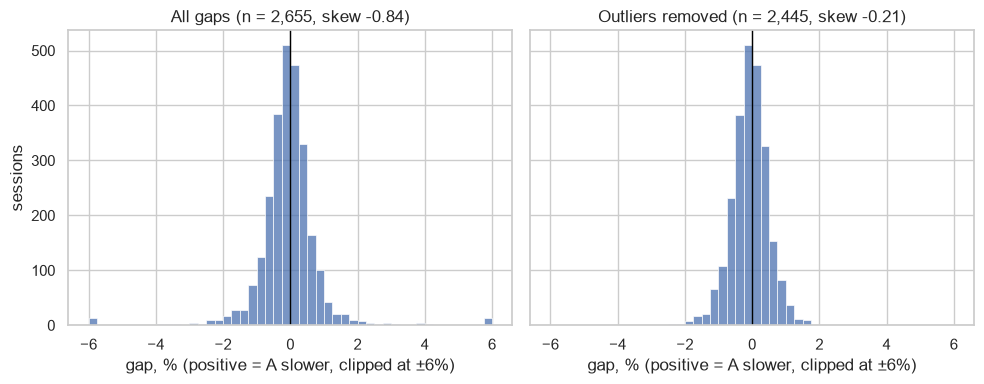

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharex=True, sharey=True)

sns.histplot(gaps['gap_clip'], bins=bins, ax=axes[0])
axes[0].set_title(f'All gaps (n = {len(gaps):,}, skew {gaps["gap"].skew():.2f})')

clean = gaps[~gaps['outlier']]
sns.histplot(clean['gap_clip'], bins=bins, ax=axes[1])
axes[1].set_title(f'Outliers removed (n = {len(clean):,}, skew {clean["gap"].skew():.2f})')

for ax in axes:
    ax.axvline(0, color='black', linewidth=1)
    ax.set_xlabel(f'gap, % (positive = A slower, clipped at ±{LIM}%)')
axes[0].set_ylabel('sessions')

plt.tight_layout()
plt.savefig(FIG / 'gap_hist_all_vs_clean.png', bbox_inches='tight')
plt.show()

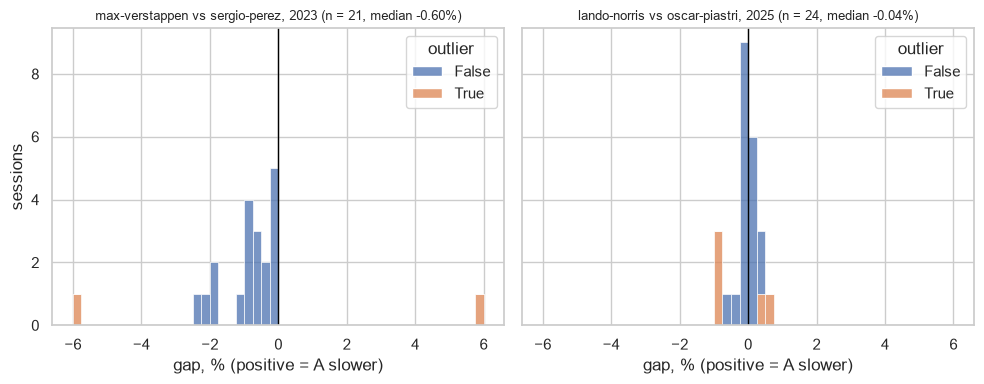

In [18]:
PAIRS = [('max-verstappen', 'sergio-perez', 2023),
         ('lando-norris', 'oscar-piastri', 2025)]

fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharex=True, sharey=True)

for ax, (a, b, yr) in zip(axes, PAIRS):
    ps = gaps[(gaps['A'] == a) & (gaps['B'] == b) & (gaps['year'] == yr)]
    sns.histplot(data=ps, x='gap_clip', hue='outlier', multiple='stack', bins=bins, ax=ax)
    ax.axvline(0, color='black', linewidth=1)
    ax.set_title(f'{a} vs {b}, {yr} (n = {len(ps)}, median {ps["gap"].median():+.2f}%)', fontsize=9)
    ax.set_xlabel('gap, % (positive = A slower)')
    ax.set_ylabel('sessions')

plt.tight_layout()
plt.savefig(FIG / 'gap_hist_pairs.png', bbox_inches='tight')
plt.show()

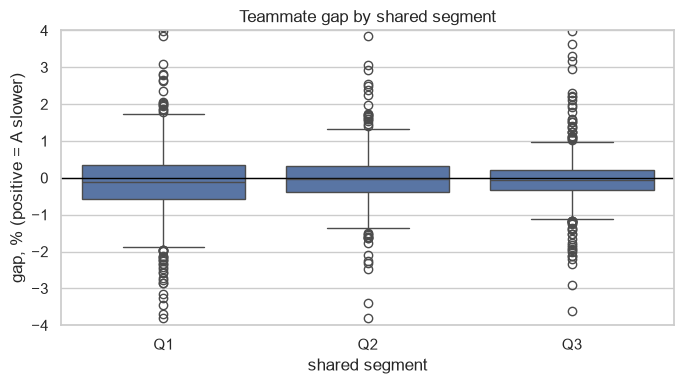

In [19]:
order = ['Q1', 'Q2', 'Q3']

plt.figure(figsize=(7, 4))
sns.boxplot(data=gaps, x='segment', y='gap', order=order)
plt.axhline(0, color='black', linewidth=1)
plt.ylim(-4, 4)
plt.xlabel('shared segment')
plt.ylabel('gap, % (positive = A slower)')
plt.title('Teammate gap by shared segment')

plt.tight_layout()
plt.savefig(FIG / 'gap_box_by_segment.png', bbox_inches='tight')
plt.show()

In [20]:
gaps.to_csv('data/teammate_gaps.csv', index=False)